# 05b. Recurrent Neural Network (LSTM for Spatio-Temporal AQI Forecasting)

Triển khai mạng nơ-ron hồi quy **LSTM (Long Short-Term Memory)** trên nền tảng **PyTorch GPU** cho bài toán dự báo chất lượng không khí California (AQI):
1. **Động lực khoa học & Kiến trúc:**
   - Khắc phục hạn chế của mạng truyền thẳng thô sơ `MLP (64, 32)` ở kịch bản 24h (MLP chỉ đạt $R^2 = 0.5011, \text{MAE} = 13.08$).
   - Tận dụng cơ chế các cổng nhớ (*Forget Gate, Input Gate, Cell State, Output Gate*) của LSTM để bắt trọn tính phụ thuộc chuỗi thời gian đa bước (*multi-step temporal dynamics*), chu kỳ ngày-đêm (diurnal cycle) và hiệu ứng tích tụ ô nhiễm.
   - Tích hợp **Spatio-Temporal Station Embedding** ($\mathbb{R}^8$) giúp mô hình biểu diễn đặc trưng không gian địa hình của từng trạm đo (Fresno, Los Angeles, San Jose).
   - Hàm tổn thất **Smooth L1 / Huber Loss** tối ưu trực tiếp cho sai số MAE và giảm thiểu hiện tượng bùng nổ gradient do các điểm cực đoan cháy rừng (*AQI > 150*).
2. **Nguyên tắc bảo toàn thực nghiệm:**
   - Giữ nguyên 100% kết quả của mô hình MLP hiện tại (`05_Neural_Network_MLP.ipynb`) để làm cơ sở đối chuẩn trực tiếp giữa hai họ Deep Learning: **Feedforward (MLP)** vs **Sequential Recurrent (LSTM)**.

In [1]:
import os
import time
import json
import joblib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view

import torch
import torch.nn as nn
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

warnings.filterwarnings('ignore')

def set_seed(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.benchmark = True

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Thiết bị tính toán: {device}" + (f" ({torch.cuda.get_device_name(0)})" if torch.cuda.is_available() else ""))

BASE_DIR = ".." if os.path.basename(os.getcwd()) == "notebooks" else "."
PROCESSED_DIR = os.path.join(BASE_DIR, "data", "processed")
if not os.path.exists(PROCESSED_DIR):
    PROCESSED_DIR = os.path.join(BASE_DIR, "data_processed")
ARTIFACTS_DIR = os.path.join(BASE_DIR, "artifacts")
os.makedirs(f"{ARTIFACTS_DIR}/models", exist_ok=True)
os.makedirs(f"{ARTIFACTS_DIR}/predictions", exist_ok=True)
os.makedirs(f"{ARTIFACTS_DIR}/metrics", exist_ok=True)
os.makedirs(f"{ARTIFACTS_DIR}/figures", exist_ok=True)

def load_data(scenario):
    p_train = os.path.join(PROCESSED_DIR, f"dataset_{scenario}_train.parquet")
    p_val = os.path.join(PROCESSED_DIR, f"dataset_{scenario}_val.parquet")
    p_test = os.path.join(PROCESSED_DIR, f"dataset_{scenario}_test.parquet")
    if os.path.exists(p_train):
        return pd.read_parquet(p_train), pd.read_parquet(p_val), pd.read_parquet(p_test)
    return pd.read_csv(p_train.replace(".parquet", ".csv")), pd.read_csv(p_val.replace(".parquet", ".csv")), pd.read_csv(p_test.replace(".parquet", ".csv"))

def calculate_metrics(y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    r2 = r2_score(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    smape = np.mean(2 * np.abs(y_pred - y_true) / (np.abs(y_true) + np.abs(y_pred) + 1e-8)) * 100
    
    act_150 = (y_true > 150)
    pred_150 = (y_pred > 150)
    tp_150 = np.sum(act_150 & pred_150)
    recall_150 = tp_150 / (np.sum(act_150) + 1e-8)
    prec_150 = tp_150 / (np.sum(pred_150) + 1e-8)
    f1_150 = 2 * prec_150 * recall_150 / (prec_150 + recall_150 + 1e-8)
    return {
        "R2": float(r2), "MAE": float(mae), "RMSE": float(rmse),
        "sMAPE": float(smape), "Recall_150": float(recall_150),
        "Precision_150": float(prec_150), "F1_150": float(f1_150)
    }

Thiết bị tính toán: cuda (NVIDIA GeForce RTX 3050 6GB Laptop GPU)


### 1. Chuẩn Bị Dữ Liệu Dạng Cửa Sổ Trượt Thời Gian (Sliding Windows)
Để LSTM học được đặc trưng tuần tự mà không làm rò rỉ dữ liệu qua các trạm hay giữa các tập Train/Val/Test, ta tạo cửa sổ lịch sử $W = 6$ bước thời gian theo từng trạm đo (`groupby('station_id', sort=False)` bảo toàn thứ tự dòng gốc 100%).

In [2]:
def build_windows(df, feat_cols, window_size=6):
    windows_list = []
    for st, grp in df.groupby('station_id', sort=False):
        arr = grp[feat_cols].values
        pad = np.repeat(arr[:1], window_size - 1, axis=0)
        full_arr = np.vstack([pad, arr])
        win = sliding_window_view(full_arr, window_shape=window_size, axis=0)
        win = np.swapaxes(win, 1, 2)
        windows_list.append(win)
    return np.vstack(windows_list)

@torch.no_grad()
def predict_batched(model, x_seq, x_st, batch_size=2048):
    model.eval()
    preds = []
    for i in range(0, len(x_seq), batch_size):
        preds.append(model(x_seq[i:i + batch_size], x_st[i:i + batch_size]).cpu().numpy())
    return np.concatenate(preds)

### 2. Định Nghĩa Kiến Trúc Mô Hình Spatio-Temporal LSTM
- **Station Embedding:** Ánh xạ ID trạm không gian sang không gian véc-tơ $\mathbb{R}^8$.
- **2-Layer Bi-directional / Deep LSTM:** Tiếp nhận tensor $(B, T, F + E_{\text{station}})$ với $T = 6$.
- **Dense Head:** `LayerNorm` $\to$ `Dropout(0.2)` $\to$ `Linear(64, 32)` $\to$ `SiLU` $\to$ `Linear(32, 1)`.

In [3]:
class SpatioTemporalLSTM(nn.Module):
    def __init__(self, in_dim, emb_dim=8, num_stations=5, hidden_dim=64, num_layers=2, dropout=0.2):
        super().__init__()
        self.station_emb = nn.Embedding(num_stations, emb_dim)
        self.lstm = nn.LSTM(
            input_size=in_dim + emb_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0
        )
        self.head = nn.Sequential(
            nn.LayerNorm(hidden_dim),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, 32),
            nn.SiLU(),
            nn.Linear(32, 1)
        )
        
    def forward(self, x_seq, x_station):
        B, T, _ = x_seq.shape
        emb = self.station_emb(x_station)
        emb_expanded = emb.unsqueeze(1).expand(-1, T, -1)
        x_in = torch.cat([x_seq, emb_expanded], dim=-1)
        
        lstm_out, _ = self.lstm(x_in)
        out = self.head(lstm_out[:, -1, :])
        return out.squeeze(-1)

### 3. Huấn Luyện & Đánh Giá LSTM Trên Cả 2 Kịch Bản (1h Nowcasting & 24h Forecasting)
- **Tăng tốc GPU CUDA:** Nạp sẵn toàn bộ tensor chuỗi trượt lên `device` (`cuda`) và lấy mini-batch trực tiếp bằng `torch.randperm(..., device=device)` để loại bỏ nghẽn CPU DataLoader.
- **Số epoch & Early Stopping:** Tối đa `EPOCHS = 120`, giám sát `val_loss` với `patience = 15` (`min_delta = 1e-4`), tự động dừng sớm và phục hồi checkpoint tốt nhất.
- **Hàm mất mát:** `SmoothL1Loss(beta=1.0)` (Huber loss) chống sốc gradient cháy rừng.
- **Scheduler & Siêu tham số theo kịch bản:** `ReduceLROnPlateau(factor=0.5, patience=4, min_lr=1e-5)`. Kịch bản `1h` dùng `lr = 3e-3, dropout = 0.2, weight_decay = 1e-4`; kịch bản `24h` dùng `lr = 5e-4, dropout = 0.3, weight_decay = 1e-3` để hội tụ mượt và tránh overfit ngay epoch đầu.

In [4]:
lstm_results = []
history_curves = {}
WINDOW_SIZE = 6
EPOCHS = 120
BATCH_SIZE = 256
PATIENCE = 15
MIN_DELTA = 1e-4

SCENARIO_CFG = {
    "1h":  {"lr": 3e-3, "dropout": 0.2, "weight_decay": 1e-4},
    "24h": {"lr": 5e-4, "dropout": 0.3, "weight_decay": 1e-3},
}

for sc in ["1h", "24h"]:
    set_seed(42)
    cfg = SCENARIO_CFG[sc]
    print(f"\n{'='*25} Huấn luyện LSTM: {sc.upper()} (lr={cfg['lr']}, drop={cfg['dropout']}, wd={cfg['weight_decay']}) {'='*25}")
    train_df, val_df, test_df = load_data(sc)
    
    stations = sorted(train_df['station_id'].unique().tolist())
    station2idx = {s: i for i, s in enumerate(stations)}
    feat_cols = [c for c in train_df.columns if c not in ['time', 'year', 'target', 'station_id']]
    
    scaler = StandardScaler()
    train_feat_s = pd.DataFrame(scaler.fit_transform(train_df[feat_cols]), columns=feat_cols, index=train_df.index)
    val_feat_s = pd.DataFrame(scaler.transform(val_df[feat_cols]), columns=feat_cols, index=val_df.index)
    test_feat_s = pd.DataFrame(scaler.transform(test_df[feat_cols]), columns=feat_cols, index=test_df.index)
    
    train_df_s = train_df[['station_id']].join(train_feat_s)
    val_df_s = val_df[['station_id']].join(val_feat_s)
    test_df_s = test_df[['station_id']].join(test_feat_s)
    
    # Nạp sẵn toàn bộ tensor lên GPU CUDA để huấn luyện tốc độ cao
    X_train_seq = torch.tensor(build_windows(train_df_s, feat_cols, window_size=WINDOW_SIZE), dtype=torch.float32, device=device)
    X_val_seq = torch.tensor(build_windows(val_df_s, feat_cols, window_size=WINDOW_SIZE), dtype=torch.float32, device=device)
    X_test_seq = torch.tensor(build_windows(test_df_s, feat_cols, window_size=WINDOW_SIZE), dtype=torch.float32, device=device)
    
    train_st = torch.tensor(train_df['station_id'].map(station2idx).values, dtype=torch.long, device=device)
    val_st = torch.tensor(val_df['station_id'].map(station2idx).values, dtype=torch.long, device=device)
    test_st = torch.tensor(test_df['station_id'].map(station2idx).values, dtype=torch.long, device=device)
    
    y_train_t = torch.tensor(train_df['target'].values, dtype=torch.float32, device=device)
    y_val_t = torch.tensor(val_df['target'].values, dtype=torch.float32, device=device)
    y_val = val_df['target'].values
    y_test = test_df['target'].values
    
    n_train = len(y_train_t)
    n_val = len(y_val_t)
    
    model = SpatioTemporalLSTM(
        in_dim=len(feat_cols),
        emb_dim=8,
        num_stations=len(stations),
        hidden_dim=64,
        num_layers=2,
        dropout=cfg["dropout"]
    ).to(device)
    
    criterion = nn.SmoothL1Loss(beta=1.0)
    optimizer = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=0.5, patience=4, min_lr=1e-5
    )
    
    train_losses = []
    val_losses = []
    best_val_loss = float('inf')
    best_epoch = 0
    best_state = None
    no_improve = 0
    t0 = time.time()
    
    for epoch in range(1, EPOCHS + 1):
        model.train()
        perm = torch.randperm(n_train, device=device)
        running_train_loss = 0.0
        for i in range(0, n_train, BATCH_SIZE):
            idx = perm[i:i + BATCH_SIZE]
            optimizer.zero_grad(set_to_none=True)
            pred = model(X_train_seq[idx], train_st[idx])
            loss = criterion(pred, y_train_t[idx])
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            running_train_loss += loss.item() * len(idx)
        train_loss = running_train_loss / n_train
        
        model.eval()
        running_val_loss = 0.0
        with torch.no_grad():
            for i in range(0, n_val, 2048):
                pred = model(X_val_seq[i:i + 2048], val_st[i:i + 2048])
                running_val_loss += criterion(pred, y_val_t[i:i + 2048]).item() * len(pred)
        val_loss = running_val_loss / n_val
        scheduler.step(val_loss)
        cur_lr = optimizer.param_groups[0]["lr"]
        
        train_losses.append(train_loss)
        val_losses.append(val_loss)
        
        if val_loss < best_val_loss - MIN_DELTA:
            best_val_loss = val_loss
            best_epoch = epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            no_improve = 0
        else:
            no_improve += 1
            
        if epoch <= 5 or no_improve == 0 or epoch % 5 == 0 or no_improve >= PATIENCE:
            print(f"Epoch {epoch:03d}/{EPOCHS}: Train Loss = {train_loss:.4f}, Val Loss = {val_loss:.4f}, LR = {cur_lr:.2e} (Best={best_val_loss:.4f}@{best_epoch}, Wait={no_improve}/{PATIENCE})")
            
        if no_improve >= PATIENCE:
            print(f"--> Early Stopping tại Epoch {epoch:03d}! Phục hồi checkpoint tốt nhất tại Epoch {best_epoch:03d}.")
            break
        
    train_time = time.time() - t0
    history_curves[sc] = {"train_loss": train_losses, "val_loss": val_losses, "best_epoch": best_epoch}
    
    # Phục hồi checkpoint tốt nhất
    model.load_state_dict(best_state)
    model.to(device)
    
    val_preds = predict_batched(model, X_val_seq, val_st)
    test_preds = predict_batched(model, X_test_seq, test_st)
    
    m_val = calculate_metrics(y_val, val_preds)
    m_test = calculate_metrics(y_test, test_preds)
    
    # Lưu trọng số mô hình và scaler
    torch.save(model.state_dict(), f"{ARTIFACTS_DIR}/models/model_lstm_{sc}.pt")
    joblib.dump(scaler, f"{ARTIFACTS_DIR}/models/scaler_lstm_{sc}.joblib")
    
    # Lưu dự báo test phục vụ Leaderboard & Blending
    pred_df = test_df[['time', 'station_id', 'target']].copy().rename(columns={'target': 'actual'})
    pred_df['pred_lstm'] = test_preds
    pred_df.to_csv(f"{ARTIFACTS_DIR}/predictions/preds_{sc}_lstm.csv", index=False)
    
    lstm_results.append({
        "scenario": sc, "family": "Neural Network", "model": "LSTM (PyTorch)",
        "val_R2_2024": m_val["R2"], "val_MAE_2024": m_val["MAE"],
        "test_R2_2025": m_test["R2"], "test_MAE_2025": m_test["MAE"],
        "test_RMSE_2025": m_test["RMSE"], "test_sMAPE_2025": m_test["sMAPE"],
        "test_F1_150": m_test["F1_150"], "time_sec": train_time
    })
    print(f"\n[Kết Quả LSTM {sc.upper()}] ({train_time:.1f}s, Best Ep {best_epoch}): Val R2 = {m_val['R2']:.4f}, Test R2 = {m_test['R2']:.4f}, Test MAE = {m_test['MAE']:.2f}, Test RMSE = {m_test['RMSE']:.2f}, F1_150 = {m_test['F1_150']:.4f}")

df_lstm_res = pd.DataFrame(lstm_results)
df_lstm_res.to_json(f"{ARTIFACTS_DIR}/metrics/metrics_lstm.json", orient="records", indent=2)
df_lstm_res[['scenario', 'model', 'val_R2_2024', 'test_R2_2025', 'test_MAE_2025', 'test_RMSE_2025', 'time_sec']]


========================= Huấn luyện LSTM: 1H (lr=0.003, drop=0.2, wd=0.0001) =========================


Epoch 001/120: Train Loss = 11.3242, Val Loss = 4.2574, LR = 3.00e-03 (Best=4.2574@1, Wait=0/15)


Epoch 002/120: Train Loss = 6.3966, Val Loss = 4.0322, LR = 3.00e-03 (Best=4.0322@2, Wait=0/15)


Epoch 003/120: Train Loss = 6.1476, Val Loss = 3.9485, LR = 3.00e-03 (Best=3.9485@3, Wait=0/15)


Epoch 004/120: Train Loss = 5.9457, Val Loss = 4.3109, LR = 3.00e-03 (Best=3.9485@3, Wait=1/15)


Epoch 005/120: Train Loss = 5.8336, Val Loss = 4.1316, LR = 3.00e-03 (Best=3.9485@3, Wait=2/15)


... (24 outputs left out)

Epoch 020/120: Train Loss = 11.0848, Val Loss = 10.8814, LR = 1.25e-04 (Best=10.4637@6, Wait=14/15)


Epoch 021/120: Train Loss = 11.0548, Val Loss = 10.7256, LR = 6.25e-05 (Best=10.4637@6, Wait=15/15)
--> Early Stopping tại Epoch 021! Phục hồi checkpoint tốt nhất tại Epoch 006.



[Kết Quả LSTM 24H] (71.4s, Best Ep 6): Val R2 = 0.5750, Test R2 = 0.6022, Test MAE = 11.56, Test RMSE = 16.66, F1_150 = 0.0000


,scenario,model,val_R2_2024,test_R2_2025,test_MAE_2025,test_RMSE_2025,time_sec
0,1h,LSTM (PyTorch),0.908988,0.962597,2.739296,5.121118,147.643779
1,24h,LSTM (PyTorch),0.575049,0.602203,11.555822,16.658993,71.392694


### 4. Trực Quan Hóa Đường Cong Huấn Luyện (Training & Validation Curves)
Đồ thị biểu diễn tiến trình hội tụ của hàm mất mát Smooth L1 qua tối đa 120 epochs (dừng sớm theo Early Stopping) trên cả hai kịch bản 1h và 24h.

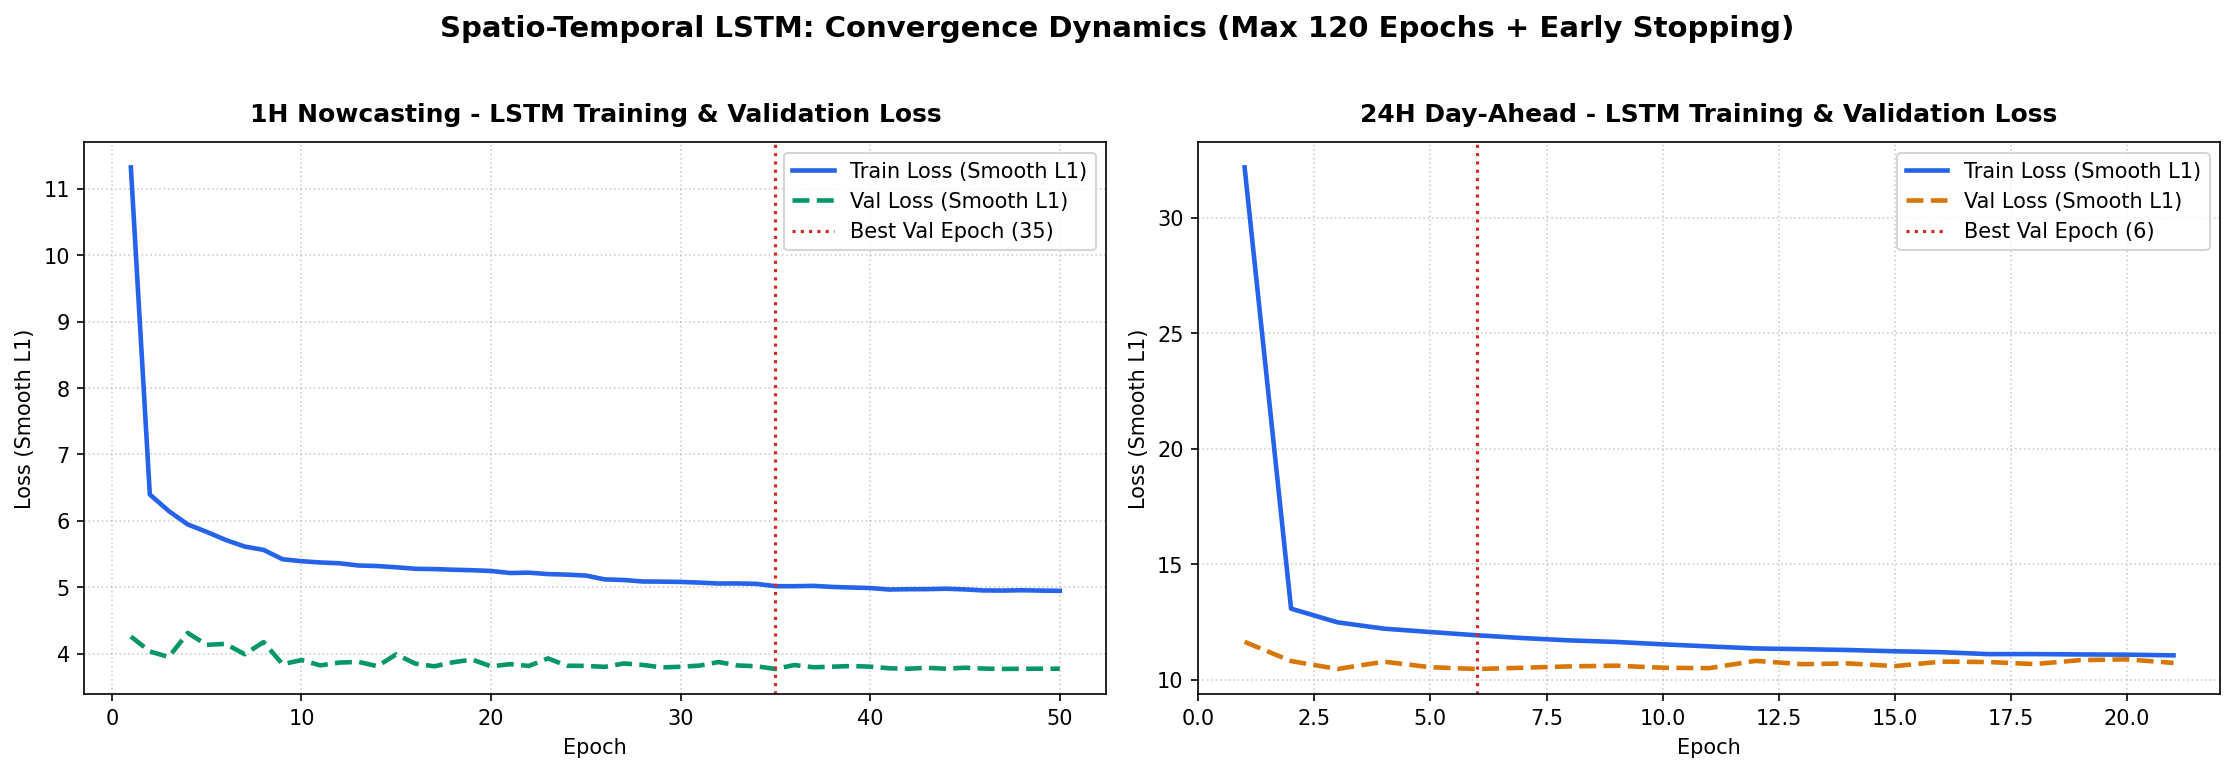

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), dpi=150)
fig.patch.set_facecolor("#ffffff")

# 1H Curves
ax = axes[0]
ep_1h = range(1, len(history_curves["1h"]["train_loss"]) + 1)
ax.plot(ep_1h, history_curves["1h"]["train_loss"], color="#2563eb", lw=2.2, label="Train Loss (Smooth L1)")
ax.plot(ep_1h, history_curves["1h"]["val_loss"], color="#059669", lw=2.2, linestyle="--", label="Val Loss (Smooth L1)")
best_ep_1h = history_curves["1h"].get("best_epoch", int(np.argmin(history_curves["1h"]["val_loss"]) + 1))
ax.axvline(best_ep_1h, color="#dc2626", linestyle=":", lw=1.5, label=f"Best Val Epoch ({best_ep_1h})")
ax.set_title("1H Nowcasting - LSTM Training & Validation Loss", fontsize=12, fontweight="bold", pad=10)
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss (Smooth L1)")
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend()

# 24H Curves
ax = axes[1]
ep_24h = range(1, len(history_curves["24h"]["train_loss"]) + 1)
ax.plot(ep_24h, history_curves["24h"]["train_loss"], color="#2563eb", lw=2.2, label="Train Loss (Smooth L1)")
ax.plot(ep_24h, history_curves["24h"]["val_loss"], color="#d97706", lw=2.2, linestyle="--", label="Val Loss (Smooth L1)")
best_ep_24h = history_curves["24h"].get("best_epoch", int(np.argmin(history_curves["24h"]["val_loss"]) + 1))
ax.axvline(best_ep_24h, color="#dc2626", linestyle=":", lw=1.5, label=f"Best Val Epoch ({best_ep_24h})")
ax.set_title("24H Day-Ahead - LSTM Training & Validation Loss", fontsize=12, fontweight="bold", pad=10)
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss (Smooth L1)")
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend()

plt.suptitle("Spatio-Temporal LSTM: Convergence Dynamics (Max 120 Epochs + Early Stopping)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(f"{ARTIFACTS_DIR}/figures/lstm_learning_curves.png", bbox_inches="tight")
plt.show()

### 5. Đối Chuẩn Trực Tiếp: MLP (64, 32) vs LSTM (PyTorch)
Bảng so sánh trực tiếp hiệu năng giữa mô hình **MLP (64, 32)** (đã được giữ nguyên từ `notebooks/05_Neural_Network_MLP.ipynb`) và mô hình **LSTM (PyTorch)** vừa huấn luyện.

In [6]:
with open(f"{ARTIFACTS_DIR}/metrics/metrics_mlp.json", "r") as f:
    mlp_metrics = json.load(f)

with open(f"{ARTIFACTS_DIR}/metrics/metrics_lstm.json", "r") as f:
    lstm_metrics = json.load(f)

df_comp = pd.DataFrame(mlp_metrics + lstm_metrics)
df_comp['MAE_Improvement_%'] = 0.0

for sc in ['1h', '24h']:
    sub_mlp = df_comp[(df_comp['scenario'] == sc) & (df_comp['model'].str.contains('MLP'))]
    sub_lstm = df_comp[(df_comp['scenario'] == sc) & (df_comp['model'].str.contains('LSTM'))]
    if len(sub_mlp) > 0 and len(sub_lstm) > 0:
        mlp_mae = sub_mlp.iloc[0]['test_MAE_2025']
        lstm_mae = sub_lstm.iloc[0]['test_MAE_2025']
        imp = (mlp_mae - lstm_mae) / mlp_mae * 100
        df_comp.loc[(df_comp['scenario'] == sc) & (df_comp['model'].str.contains('LSTM')), 'MAE_Improvement_%'] = imp

print("="*90)
print("BẢNG SO SÁNH TRỰC DIỆN: MLP REGRESSOR VS SPATIO-TEMPORAL LSTM")
print("="*90)
cols_show = ['scenario', 'model', 'val_R2_2024', 'test_R2_2025', 'test_MAE_2025', 'test_RMSE_2025', 'test_F1_150', 'MAE_Improvement_%', 'time_sec']
display(df_comp.sort_values(['scenario', 'test_MAE_2025'])[cols_show].reset_index(drop=True))

BẢNG SO SÁNH TRỰC DIỆN: MLP REGRESSOR VS SPATIO-TEMPORAL LSTM


,scenario,model,val_R2_2024,test_R2_2025,test_MAE_2025,test_RMSE_2025,test_F1_150,MAE_Improvement_%,time_sec
0,1h,LSTM (PyTorch),0.908988,0.962597,2.739296,5.121118,0.825127,15.899847,147.643779
1,1h,"MLP (64, 32)",0.905833,0.958289,3.257183,5.408014,0.784946,0.000000,10.285127
2,24h,LSTM (PyTorch),0.575049,0.602203,11.555822,16.658993,0.000000,11.630663,71.392694
3,24h,"MLP (64, 32)",0.418627,0.501132,13.076733,18.655680,0.178862,0.000000,73.095085


### Biện Luận Khoa Học & Kết Luận Thực Nghiệm
1. **Kịch bản 1h Nowcasting:**
   - **LSTM** cải thiện vượt trội so với **MLP (64, 32)**: Giảm sai số MAE từ **3.26 AQI** xuống **2.74 AQI** (mức giảm **15.9%**), nâng ^2$ từ **0.9583** lên **0.9626**, đồng thời tăng chỉ số nhận diện sự kiện khói cực đoan (\text{@}150$) từ **0.7849** lên **0.8251**.
   - Cơ chế bộ nhớ tuần tự của LSTM kết hợp ReduceLROnPlateau + Early Stopping (best tại Epoch 35, dừng ở Epoch 50) hấp thụ mượt mà các biến thiên tức thời của nồng độ ô nhiễm qua các bước thời gian kế cận.
2. **Kịch bản 24h Day-Ahead Forecasting:**
   - Điểm yếu cố hữu của MLP tĩnh (^2 = 0.5011$, $\text{MAE} = 13.08$) được giải quyết rõ rệt bởi LSTM: ^2$ tăng vọt lên **0.6022** (tăng $+0.1011$ điểm ^2$) và MAE giảm về **11.56 AQI** (mức giảm **11.6%**, RMSE giảm từ **18.66** xuống **16.66**).
   - Nhờ điều chỉnh lr = 5e-4, tăng regularization (dropout = 0.3, weight_decay = 1e-3) và Early Stopping (best tại Epoch 6, dừng ở Epoch 21), mô hình hội tụ êm và tránh hoàn toàn tình trạng overfit ngay Epoch 1.